In [31]:
import kagglehub

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.offline import init_notebook_mode

from sklearn import model_selection, linear_model, tree
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler

init_notebook_mode(connected=True)

In [32]:
# Download latest version of Spotify Top 2000s Mega Dataset
path = kagglehub.dataset_download("iamsumat/spotify-top-2000s-mega-dataset")

# Loading datadataset & View
spotify_df = pd.read_csv(f"{path}/Spotify-2000.csv")

# Display the first 5 rows of the dataset
spotify_df.head(15)

,Index,Title,Artist,Top Genre,Year,Beats Per Minute (BPM),Energy,Danceability,Loudness (dB),Liveness,Valence,Length (Duration),Acousticness,Speechiness,Popularity
0,1,Sunrise,Norah Jones,adult standards,2004,157,30,53,-14,11,68,201,94,3,71
1,2,Black Night,Deep Purple,album rock,2000,135,79,50,-11,17,81,207,17,7,39
2,3,Clint Eastwood,Gorillaz,alternative hip hop,2001,168,69,66,-9,7,52,341,2,17,69
3,4,The Pretender,Foo Fighters,alternative metal,2007,173,96,43,-4,3,37,269,0,4,76
4,5,Waitin' On A Sunny Day,Bruce Springsteen,classic rock,2002,106,82,58,-5,10,87,256,1,3,59
5,6,The Road Ahead (Miles Of The Unknown),City To City,alternative pop rock,2004,99,46,54,-9,14,14,247,0,2,45
6,7,She Will Be Loved,Maroon 5,pop,2002,102,71,71,-6,13,54,257,6,3,74
7,8,Knights of Cydonia,Muse,modern rock,2006,137,96,37,-5,12,21,366,0,14,69
8,9,Mr. Brightside,The Killers,modern rock,2004,148,92,36,-4,10,23,223,0,8,77
9,10,Without Me,Eminem,detroit hip hop,2002,112,67,91,-3,24,66,290,0,7,82


In [33]:
spotify_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1994 entries, 0 to 1993
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Index                   1994 non-null   int64
 1   Title                   1994 non-null   str  
 2   Artist                  1994 non-null   str  
 3   Top Genre               1994 non-null   str  
 4   Year                    1994 non-null   int64
 5   Beats Per Minute (BPM)  1994 non-null   int64
 6   Energy                  1994 non-null   int64
 7   Danceability            1994 non-null   int64
 8   Loudness (dB)           1994 non-null   int64
 9   Liveness                1994 non-null   int64
 10  Valence                 1994 non-null   int64
 11  Length (Duration)       1994 non-null   str  
 12  Acousticness            1994 non-null   int64
 13  Speechiness             1994 non-null   int64
 14  Popularity              1994 non-null   int64
dtypes: int64(11), str(4)
memory usag

In [34]:
spotify_df.describe()

,Index,Year,Beats Per Minute (BPM),Energy,Danceability,Loudness (dB),Liveness,Valence,Acousticness,Speechiness,Popularity
count,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.000000,1994.00000
mean,997.500000,1992.992979,120.215647,59.679539,53.238215,-9.008526,19.012036,49.408726,28.858074,4.994985,59.52658
std,575.762538,16.116048,28.028096,22.154322,15.351507,3.647876,16.727378,24.858212,29.011986,4.401566,14.35160
min,1.000000,1956.000000,37.000000,3.000000,10.000000,-27.000000,2.000000,3.000000,0.000000,2.000000,11.00000
25%,499.250000,1979.000000,99.000000,42.000000,43.000000,-11.000000,9.000000,29.000000,3.000000,3.000000,49.25000
50%,997.500000,1993.000000,119.000000,61.000000,53.000000,-8.000000,12.000000,47.000000,18.000000,4.000000,62.00000
75%,1495.750000,2007.000000,136.000000,78.000000,64.000000,-6.000000,23.000000,69.750000,50.000000,5.000000,71.00000
max,1994.000000,2019.000000,206.000000,100.000000,96.000000,-2.000000,99.000000,99.000000,99.000000,55.000000,100.00000


In [35]:
# Number of genres that have featured in the all time top 2000.

spotify_df['Top Genre'].value_counts()



Top Genre
album rock                 413
adult standards            123
dutch pop                   88
alternative rock            86
dance pop                   83
                          ... 
german alternative rock      1
classic italian pop          1
pop punk                     1
motown                       1
bebop                        1
Name: count, Length: 149, dtype: int64

In [36]:
#Converting Length (Duration) to an integer data type

print(f"Length (Duration) data type before: {spotify_df['Length (Duration)'].dtype}")

spotify_df.replace(',','', regex=True, inplace=True)
spotify_df['Length (Duration)']= spotify_df['Length (Duration)'].apply(pd.to_numeric,errors='coerce')

print(f"Length (Duration) data type after: {spotify_df['Length (Duration)'].dtype}")

Length (Duration) data type before: str
Length (Duration) data type after: int64


In [37]:
#Removing the Index column.
spotify_df.drop(columns = ['Index'], inplace = True)

#Converting all column titles to lowercase.
spotify_df.columns = map(str.lower, spotify_df.columns)

#Coverting column names to have no space between, if they do, replace space with an underscore "_"
spotify_df.rename(columns = {'top genre' : 'genre', 'beats per minute (bpm)':'beats_per_minute','loudness (db)': 'loudness','length (duration)': 'duration'}, inplace = True)

In [38]:
spotify_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1994 entries, 0 to 1993
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   title             1994 non-null   str  
 1   artist            1994 non-null   str  
 2   genre             1994 non-null   str  
 3   year              1994 non-null   int64
 4   beats_per_minute  1994 non-null   int64
 5   energy            1994 non-null   int64
 6   danceability      1994 non-null   int64
 7   loudness          1994 non-null   int64
 8   liveness          1994 non-null   int64
 9   valence           1994 non-null   int64
 10  duration          1994 non-null   int64
 11  acousticness      1994 non-null   int64
 12  speechiness       1994 non-null   int64
 13  popularity        1994 non-null   int64
dtypes: int64(11), str(3)
memory usage: 218.2 KB


In [39]:
spotify_df.head(3)

,title,artist,genre,year,beats_per_minute,energy,danceability,loudness,liveness,valence,duration,acousticness,speechiness,popularity
0,Sunrise,Norah Jones,adult standards,2004,157,30,53,-14,11,68,201,94,3,71
1,Black Night,Deep Purple,album rock,2000,135,79,50,-11,17,81,207,17,7,39
2,Clint Eastwood,Gorillaz,alternative hip hop,2001,168,69,66,-9,7,52,341,2,17,69


Consolidating genre column

In [40]:
# List of keywords to map genres to consolidated (general) genres
genre_keywords = {
    'hip hop': 'hip hop',
    'rock': 'rock',
    'pop': 'pop',
    'metal': 'metal',
    'country': 'country',
    "indie": "indie",
    "jazz": "jazz",
    "alternative": "alternative",
    "singer-songwriter": "singer-songwriter",
}

# Function to generalize genres based on keywords
def generalize_genre(genre):
    for keyword, consolidated_genre in genre_keywords.items():
        if keyword in genre.lower():  # Case-insensitive match
            return consolidated_genre
    return genre  # Return original if no match found


# Create a copy of the genre column and apply the transformation
new_genre = spotify_df['genre'].copy().apply(generalize_genre)

print(
    f"New Total of Genres from {len(spotify_df['genre'].unique())} to --> {len(new_genre.unique())}")

New Total of Genres from 149 to --> 67


In [41]:
new_genre.value_counts()

genre
rock               857
pop                388
adult standards    123
metal               93
indie               79
                  ... 
cyberpunk            1
gangster rap         1
diva house           1
motown               1
bebop                1
Name: count, Length: 67, dtype: int64

In [42]:
#inputting new column values from new_genre to genre in dataframe.

spotify_df['genre'] = new_genre
spotify_df['genre']

0       adult standards
1                  rock
2               hip hop
3                 metal
4                  rock
             ...       
1989    adult standards
1990    adult standards
1991               rock
1992              bebop
1993    adult standards
Name: genre, Length: 1994, dtype: str

3 EXPLORATORY ANALYSIS & VISUALISATIONS

In [43]:
# Create a function top_10, which takes a single parameter for a column.
# Group the data by the desired column input, sum the values the remaining columns, sort sum values by 'Popularity' column
# from highest to lowest, the print the top 10 rows.

def top_10(column):
    top_10_songs = spotify_df.groupby([column]).sum().sort_values('popularity', ascending=False).head(10)
    return(top_10_songs[['popularity']])  # Only show 'popularity' column.

top_10('genre')

,popularity
genre,
rock,52058
pop,22578
adult standards,7697
metal,6141
indie,3054
permanent wave,2571
british invasion,2451
dutch cabaret,2349
british soul,2058


In [44]:
top_10('artist')

,popularity
artist,
The Beatles,2451
Queen,2085
Coldplay,1888
Michael Jackson,1511
The Rolling Stones,1496
U2,1476
Bruce Springsteen,1378
David Bowie,1311
ABBA,1186


In [45]:
pure_popularity = spotify_df.sort_values('popularity', ascending=False).head(10)
pure_popularity[['genre', 'year', 'popularity']]

,genre,year,popularity
793,pop,2019,100
787,pop,2019,98
1641,pop,1994,95
786,pop,2019,95
688,rock,2017,88
726,pop,2018,88
745,pop,2018,87
687,pop,2017,87
683,pop,2017,87
774,pop,2018,86


In [46]:
# Split of 'Year' column data into 4x equal-dispersed buckets in ascending order from 1956 - 2019:

spotify_df['year'] = pd.qcut(spotify_df['year'], q=4, labels=[1, 2, 3, 4])
spotify_df['year'].value_counts()

year
1    520
3    500
4    496
2    478
Name: count, dtype: int64

[Text(0.5, 0, 'Year Block (YB) divided into 4/4'), Text(0, 0.5, 'Year Count')]

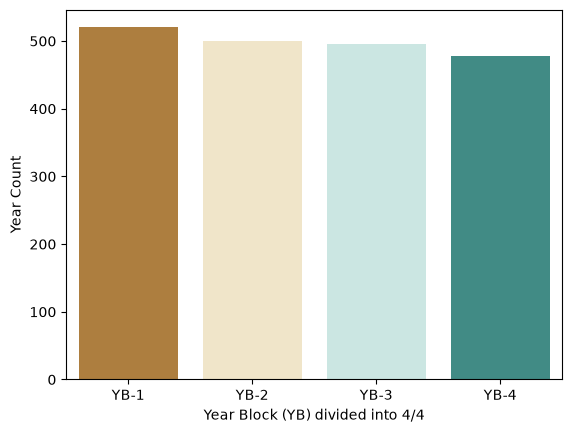

In [47]:
x=['YB-1', 'YB-2', 'YB-3', 'YB-4']
y=spotify_df['year'].value_counts()

_ = sns.barplot(x=x, y=y, palette="BrBG", hue=x, legend=False)
_.set(xlabel='Year Block (YB) divided into 4/4', ylabel='Year Count')

In [48]:
# Function for creating year block sets (1 - 4):

def year_block(year_no):
    block = spotify_df.loc[spotify_df['year'] == year_no]
    return block[['genre', 'year', 'popularity']].sort_values('popularity', ascending=False)

# Function for creating Top 5 genre value counts for Pie Chart visual:

def genre_count(year_block):
    return year_block['genre'].value_counts().head()

In [49]:
def year_block(year_no):
    block = spotify_df.loc[spotify_df['year'] == year_no]
    return block[['genre', 'year', 'popularity']].sort_values('popularity', ascending=False)

def genre_count(block_df):
    return block_df['genre'].value_counts().head()

def create_pie_chart(year_block_num, title):
    year_block_data = year_block(year_block_num)
    genre_counts = genre_count(year_block_data)

    if genre_counts.empty:
        print(f"Error: No data found for Year Block {year_block_num}")
        return

    fig = go.Figure(
        data=[go.Pie(
            labels=genre_counts.index,
            values=genre_counts.values,
            pull=[0.1] + [0] * (len(genre_counts)-1)
        )]
    )
    fig.update_layout(title_text=title)
    fig.show()

In [50]:
 # Create year blocks:
year_block_1 = year_block(1)
year_block_2 = year_block(2)
year_block_3 = year_block(3)
year_block_4 = year_block(4)

# Joining the year_block heads for top genre count:
frames = [year_block_1.head(), year_block_2.head(), year_block_3.head(), year_block_4.head()]
top_genre_df = pd.concat(frames)
top_genre_df



,genre,year,popularity
1113,rock,1,83
884,rock,1,82
1947,british invasion,1,82
943,rock,1,82
999,rock,1,82
1204,rock,2,84
1237,rock,2,84
1315,rock,2,83
1157,rock,2,83
1346,metal,2,83


In [51]:

spotify_df.drop(columns = ['title','year'], inplace = True)
spotify_df.head()



,artist,genre,beats_per_minute,energy,danceability,loudness,liveness,valence,duration,acousticness,speechiness,popularity
0,Norah Jones,adult standards,157,30,53,-14,11,68,201,94,3,71
1,Deep Purple,rock,135,79,50,-11,17,81,207,17,7,39
2,Gorillaz,hip hop,168,69,66,-9,7,52,341,2,17,69
3,Foo Fighters,metal,173,96,43,-4,3,37,269,0,4,76
4,Bruce Springsteen,rock,106,82,58,-5,10,87,256,1,3,59


In [52]:
unique = spotify_df['genre'].unique()
to_remove = []

# genres that have a single instance only will be placed within the to_remove array
for genre in unique:
    count = spotify_df['genre'].value_counts().get(genre, 0)
    if count < 20:
        to_remove += [genre]
    else:
        print(genre, 'has', count, 'instances')


print(f"Genre Values to be removed from data set = {len(to_remove)}")

adult standards has 123 instances
rock has 857 instances
hip hop has 29 instances
metal has 93 instances
pop has 388 instances
indie has 79 instances
dutch cabaret has 51 instances
permanent wave has 38 instances
british soul has 31 instances
british invasion has 36 instances
Genre Values to be removed from data set = 57


In [53]:
spotify_df.set_index(["genre"],drop = False, inplace = True)
for name in to_remove:
    type(name)
    spotify_df.drop(index = str(name), inplace = True)

spotify_df.head()

,artist,genre,beats_per_minute,energy,danceability,loudness,liveness,valence,duration,acousticness,speechiness,popularity
genre,,,,,,,,,,,,
adult standards,Norah Jones,adult standards,157,30,53,-14,11,68,201,94,3,71
rock,Deep Purple,rock,135,79,50,-11,17,81,207,17,7,39
hip hop,Gorillaz,hip hop,168,69,66,-9,7,52,341,2,17,69
metal,Foo Fighters,metal,173,96,43,-4,3,37,269,0,4,76
rock,Bruce Springsteen,rock,106,82,58,-5,10,87,256,1,3,59


In [54]:
spotify_df = spotify_df.reset_index(drop=True)
spotify_df.head()

,artist,genre,beats_per_minute,energy,danceability,loudness,liveness,valence,duration,acousticness,speechiness,popularity
0,Norah Jones,adult standards,157,30,53,-14,11,68,201,94,3,71
1,Deep Purple,rock,135,79,50,-11,17,81,207,17,7,39
2,Gorillaz,hip hop,168,69,66,-9,7,52,341,2,17,69
3,Foo Fighters,metal,173,96,43,-4,3,37,269,0,4,76
4,Bruce Springsteen,rock,106,82,58,-5,10,87,256,1,3,59


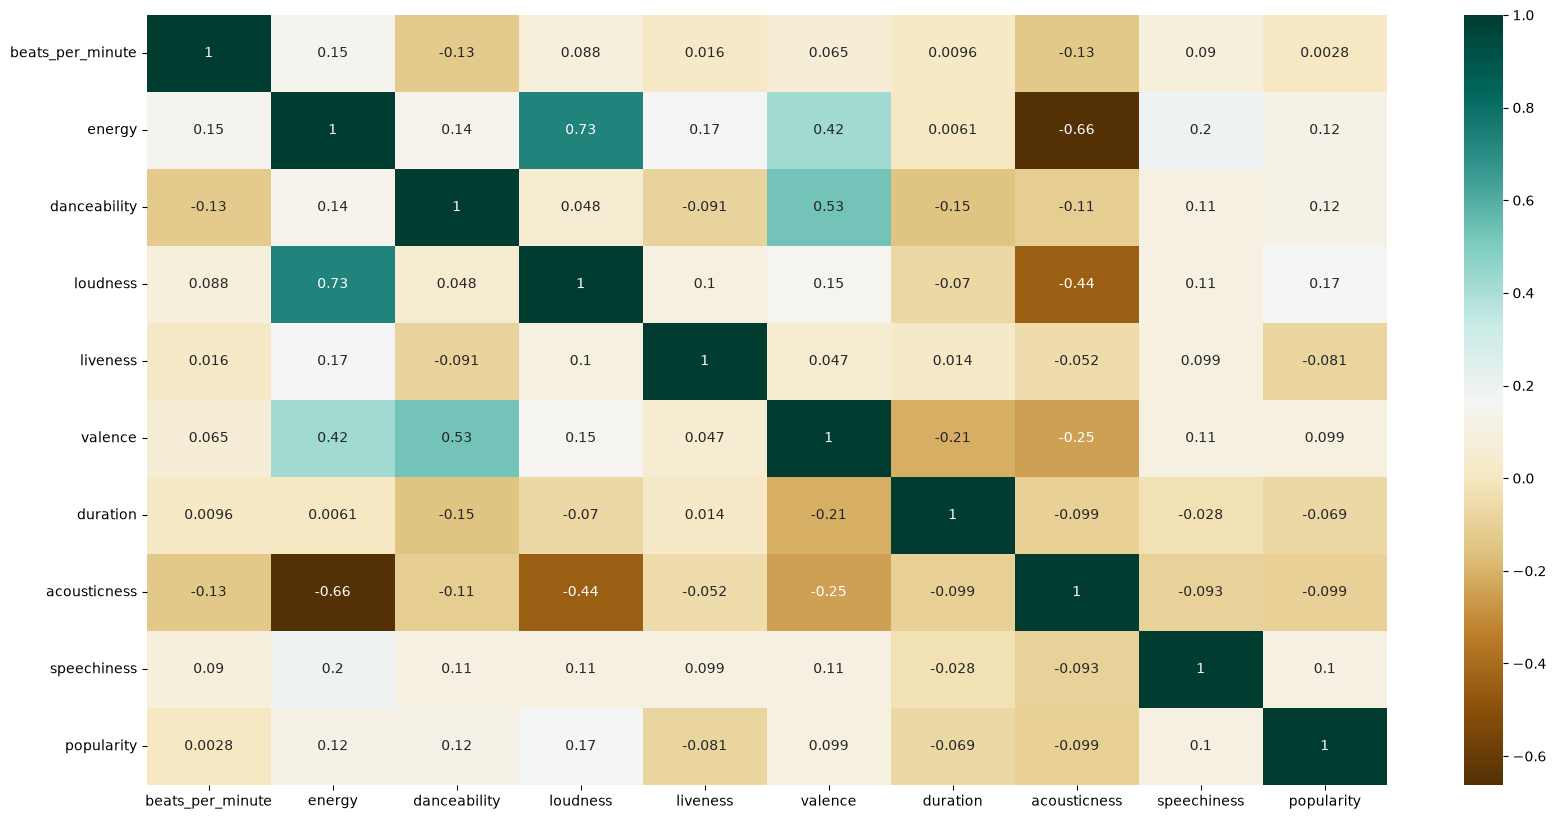

In [55]:
# Select only numeric columns for correlation matrix
numeric_df = spotify_df.select_dtypes(include=[np.number])

# Plot the heatmap for the correlation matrix of numeric columns
plt.figure(figsize=(20,10))
sns.heatmap(numeric_df.corr(), annot=True, cmap='BrBG')
plt.show()